# 01. EDA: Bank Account Fraud (BAF)
Məqsəd: datanı anlamaq və preprocessing qərarları üçün sübut toplamaq.

## 1. Setup

In [1]:
# Kitabxanalar və layihə sabitləri (sütun siyahıları src/config.py-dədir)
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DATA_PATH, TARGET, TIME_COL, CATEGORICAL, MISSING_MINUS1, NEGATIVE_MISSING

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Data Loading

In [2]:
# Datanı bir dəfə yükləyirik; bütün EDA bu df üzərindədir
def load_data(path: str) -> pd.DataFrame:
    """CSV oxuyur və ölçüsünü çap edir."""
    df = pd.read_csv(path)
    print(f"Shape: {df.shape}")
    return df

df = load_data(DATA_PATH)
df.head()

Shape: (1000000, 32)


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## 3. Data Structure

In [3]:
# Tiplər, boş dəyərlər və təsviri statistika
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  str    
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000000 non-nul

,count,mean,std,min,25%,50%,75%,max
fraud_bool,1000000.0,0.011029,0.104438,0.000000e+00,0.000000,0.000000,0.000000,1.000000
income,1000000.0,0.562696,0.290343,1.000000e-01,0.300000,0.600000,0.800000,0.900000
name_email_similarity,1000000.0,0.493694,0.289125,1.434550e-06,0.225216,0.492153,0.755567,0.999999
prev_address_months_count,1000000.0,16.718568,44.046230,-1.000000e+00,-1.000000,-1.000000,12.000000,383.000000
current_address_months_count,1000000.0,86.587867,88.406599,-1.000000e+00,19.000000,52.000000,130.000000,428.000000
customer_age,1000000.0,33.689080,12.025799,1.000000e+01,20.000000,30.000000,40.000000,90.000000
days_since_request,1000000.0,1.025705,5.381835,4.036860e-09,0.007193,0.015176,0.026331,78.456904
intended_balcon_amount,1000000.0,8.661499,20.236155,-1.553055e+01,-1.181488,-0.830507,4.984176,112.956928
zip_count_4w,1000000.0,1572.692049,1005.374565,1.000000e+00,894.000000,1263.000000,1944.000000,6700.000000
velocity_6h,1000000.0,5665.296605,3009.380665,-1.706031e+02,3436.365848,5319.769349,7680.717827,16715.565404


### Duplicate və sabit sütunlar
Sabit sütun modelə məlumat vermir, ona görə drop namizədidir.

In [4]:
# Dublikat və sabit sütunlar: sabit sütun modelə məlumat vermir, drop qərarı buradan gəlir
print("Duplicate sətir:", df.duplicated().sum())
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Sabit sütunlar:", const_cols)

Duplicate sətir: 0
Sabit sütunlar: ['device_fraud_count']


## 4. Target Distribution

Fraud rate: 1.1029%


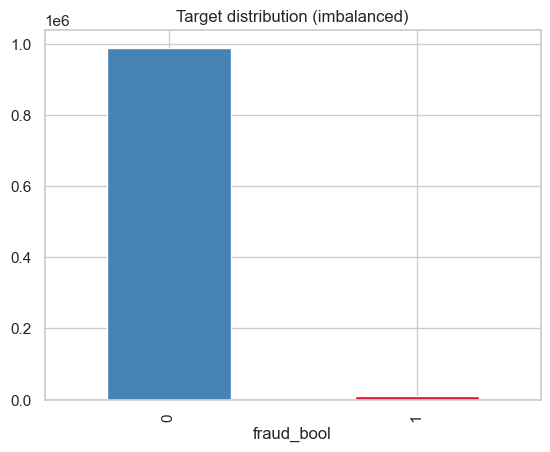

In [5]:
# Target balansı: ~1% fraud, ona görə accuracy yox, PR-AUC istifadə olunur
print(f"Fraud rate: {df[TARGET].mean():.4%}")
df[TARGET].value_counts().plot(kind="bar", color=["steelblue", "crimson"])
plt.title("Target distribution (imbalanced)")
plt.show()

## 5. Missing Values
BAF-da missing `-1` (və `intended_balcon_amount` üçün mənfi dəyər) kimi kodlanıb.

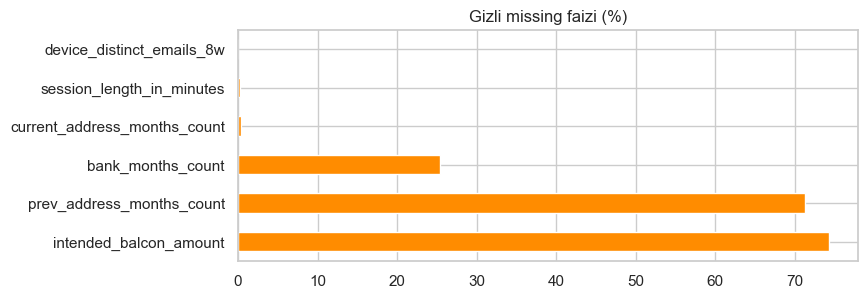

,missing_pct
intended_balcon_amount,74.2523
prev_address_months_count,71.2920
bank_months_count,25.3635
current_address_months_count,0.4254
session_length_in_minutes,0.2015
device_distinct_emails_8w,0.0359


In [6]:
# BAF-da -1 / mənfi dəyər real ölçü deyil, 'məlumat yoxdur' kodudur; faizini hesablayırıq
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    """Hər sütunda gizli missing faizini qaytarır (-1 və ya mənfi kod)."""
    rows = {}
    for c in MISSING_MINUS1:
        rows[c] = (df[c] == -1).mean() * 100
    for c in NEGATIVE_MISSING:
        rows[c] = (df[c] < 0).mean() * 100
    return pd.Series(rows, name="missing_pct").sort_values(ascending=False).to_frame()

mr = missing_report(df)
mr.plot(kind="barh", legend=False, figsize=(8, 3), color="darkorange")
plt.title("Gizli missing faizi (%)")
plt.show()
mr

### Missing ilə fraud əlaqəsi
Missing-in özü siqnaldırsa, indikator feature saxlayırıq.

In [7]:
# Missing-in özü siqnaldırmı? Çatışan və mövcud sətirlərdə fraud faizini müqayisə edirik
rows = []
for c in MISSING_MINUS1 + NEGATIVE_MISSING:
    miss = (df[c] == -1) if c in MISSING_MINUS1 else (df[c] < 0)
    rows.append({"feature": c,
                 "fraud_rate_if_missing": df.loc[miss, TARGET].mean(),
                 "fraud_rate_if_present": df.loc[~miss, TARGET].mean()})
pd.DataFrame(rows).set_index("feature")

,fraud_rate_if_missing,fraud_rate_if_present
feature,,
prev_address_months_count,0.014215,0.003118
current_address_months_count,0.003291,0.011062
bank_months_count,0.016323,0.009230
session_length_in_minutes,0.008933,0.011033
device_distinct_emails_8w,0.011142,0.011029
intended_balcon_amount,0.013127,0.004979


## 6. Numeric Distributions

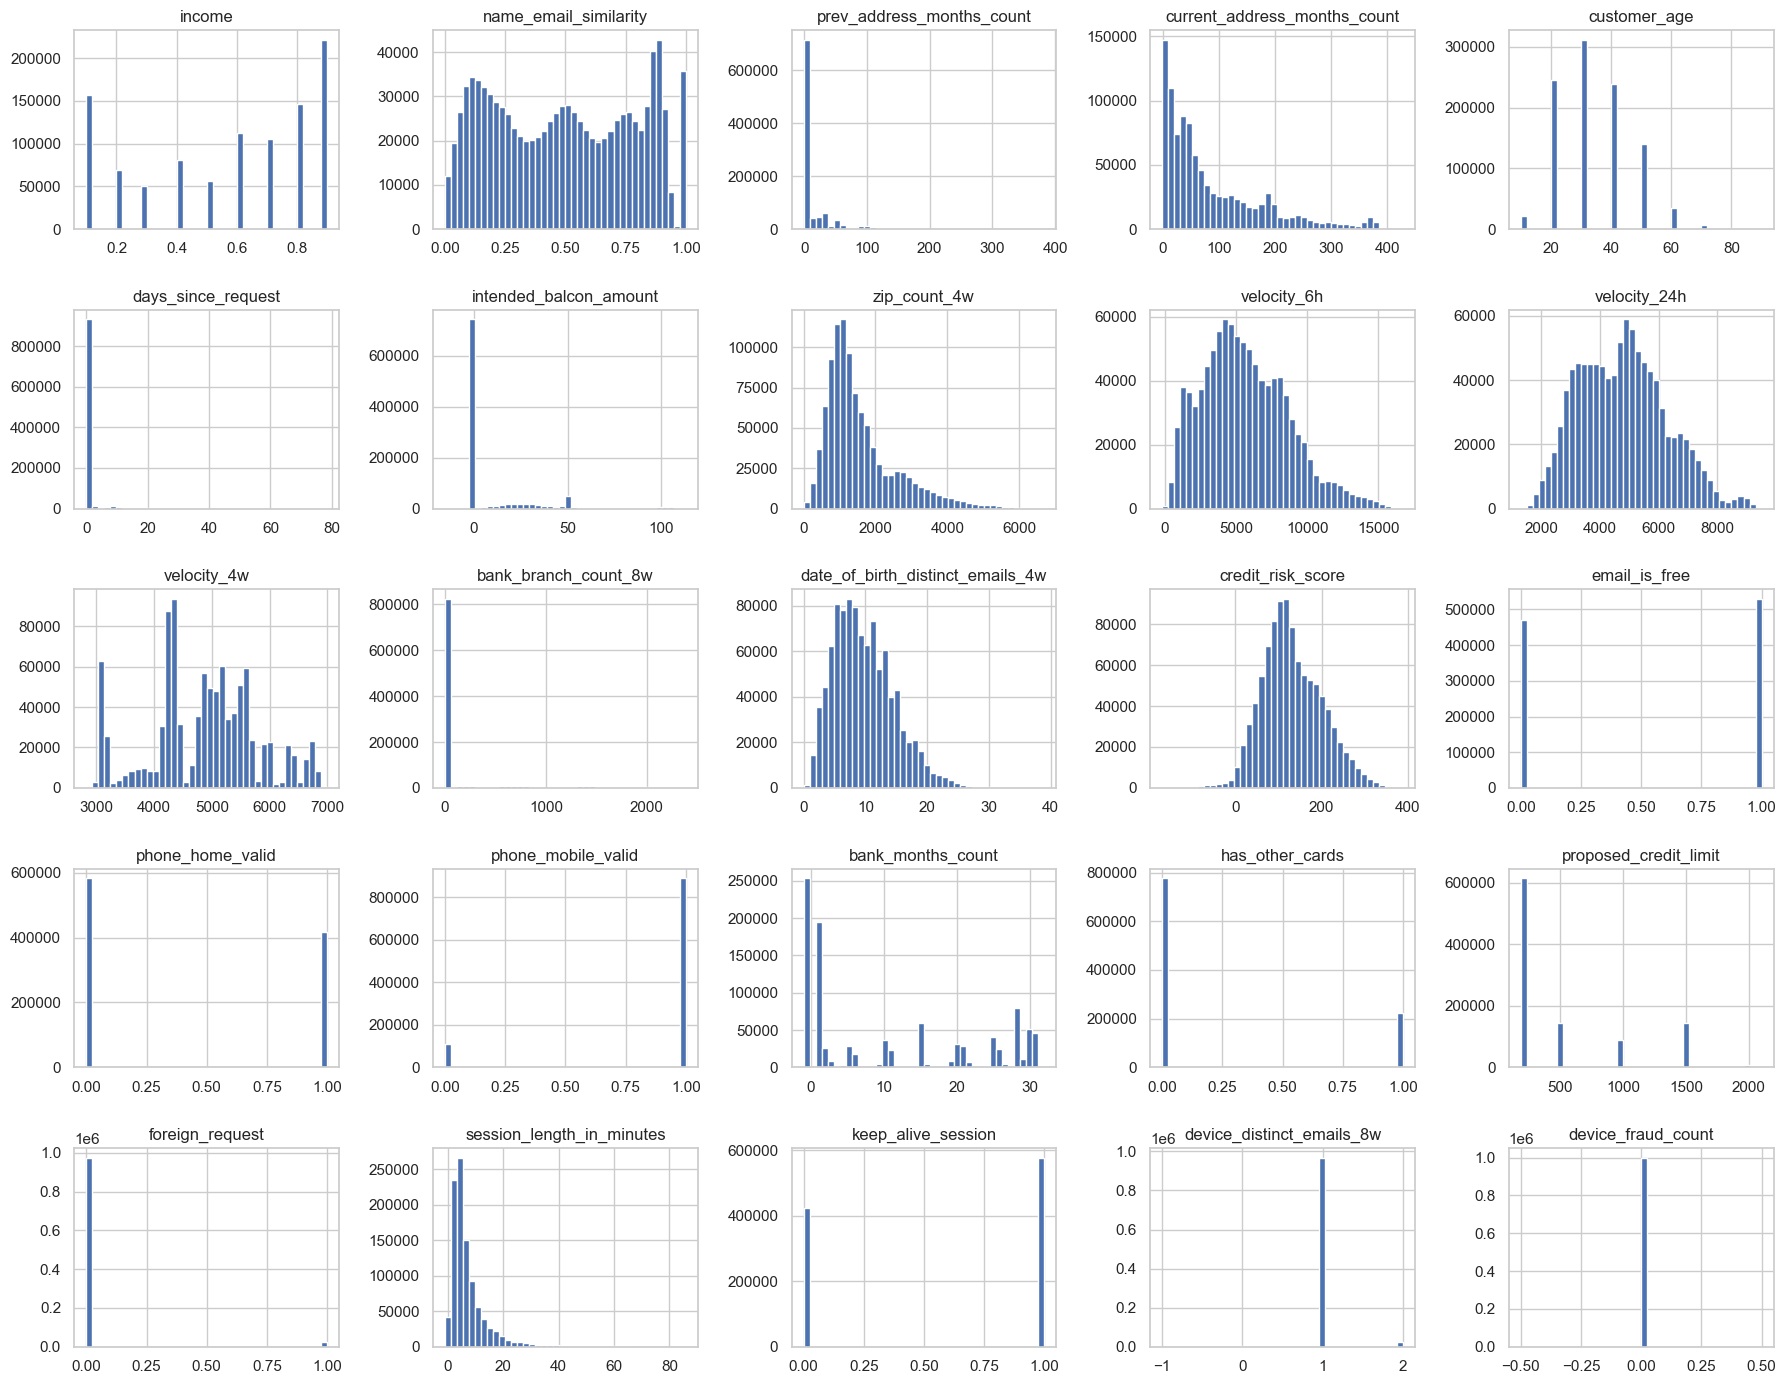

In [8]:
# Rəqəmsal paylanmalar: çəpliyi və ağır quyruqları görmək üçün
num_cols = df.select_dtypes("number").columns.drop([TARGET, TIME_COL])
df[num_cols].hist(bins=40, figsize=(18, 14))
plt.tight_layout()
plt.show()

### Outlier payı (IQR qaydası)
Fraud özü kənar dəyər kimi görünə bilər, ona görə kütləvi silmə riskli.

In [9]:
# Outlier payı (IQR). Silmirik, çünki fraud kənar dəyərlərdə cəmləşə bilər
def iqr_outlier_share(s: pd.Series) -> float:
    """1.5*IQR qaydasına görə kənar dəyər payı."""
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean()

# Binary (0/1) sütunlarda IQR qaydası mənasızdır, onları çıxarırıq
non_binary = [c for c in num_cols if df[c].nunique() > 2]
out = pd.Series({c: iqr_outlier_share(df[c]) for c in non_binary}).sort_values(ascending=False)
out.head(8).to_frame("outlier_share")

,outlier_share
proposed_credit_limit,0.241742
intended_balcon_amount,0.222702
bank_branch_count_8w,0.175243
prev_address_months_count,0.157320
days_since_request,0.094834
session_length_in_minutes,0.078789
zip_count_4w,0.059871
current_address_months_count,0.041001


## 7. Categorical Features

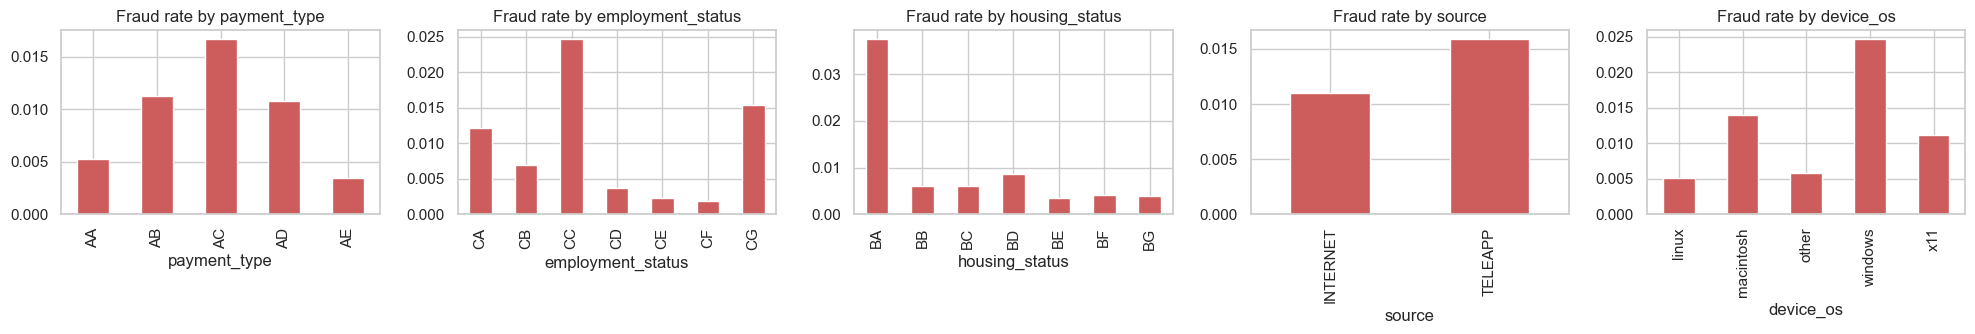

In [10]:
# Kateqorik dəyişənlər üzrə fraud faizi (hansı səviyyə daha riskli)
fig, axes = plt.subplots(1, len(CATEGORICAL), figsize=(20, 3.5))
for ax, c in zip(axes, CATEGORICAL):
    df.groupby(c)[TARGET].mean().plot(kind="bar", ax=ax, color="indianred")
    ax.set_title(f"Fraud rate by {c}")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 8. Relationships with Target

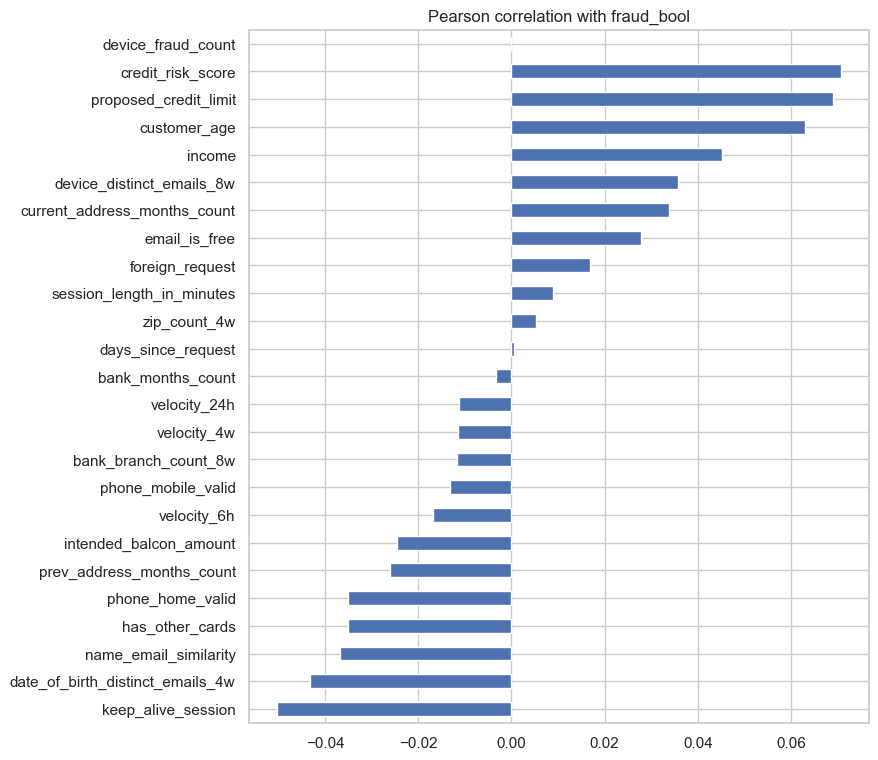

In [11]:
# Xətti əlaqə (Pearson). Yalnız xətti əlaqəni göstərir, qeyri-xətti əlaqə növbəti hüceyrədədir
corr = df[num_cols].corrwith(df[TARGET]).sort_values()
corr.plot(kind="barh", figsize=(8, 9))
plt.title("Pearson correlation with fraud_bool")
plt.show()

### Fraud rate by bins (xətti olmayan əlaqə)

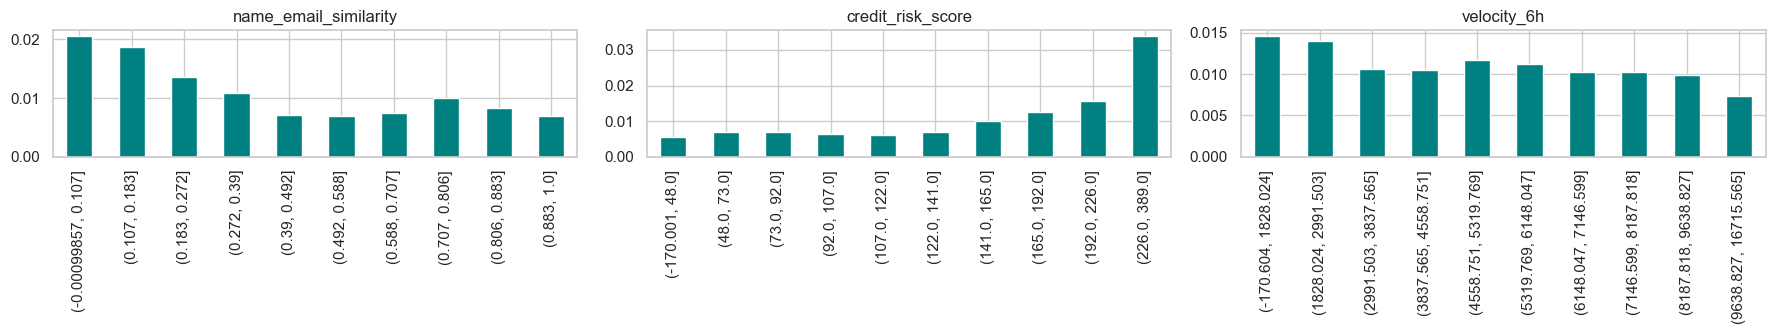

In [12]:
# Kvantil bin-lərlə qeyri-xətti əlaqə: fraud faizi feature artdıqca necə dəyişir
def fraud_rate_by_bin(col: str, q: int = 10) -> pd.Series:
    """Feature-i kvantil bin-lərə bölüb hər bin-də fraud faizini qaytarır."""
    return df.groupby(pd.qcut(df[col], q, duplicates="drop"), observed=True)[TARGET].mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, c in zip(axes, ["name_email_similarity", "credit_risk_score", "velocity_6h"]):
    fraud_rate_by_bin(c).plot(kind="bar", ax=ax, color="teal")
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### Multicollinearity
Velocity sütunları bir-biri ilə əlaqəli ola bilər.

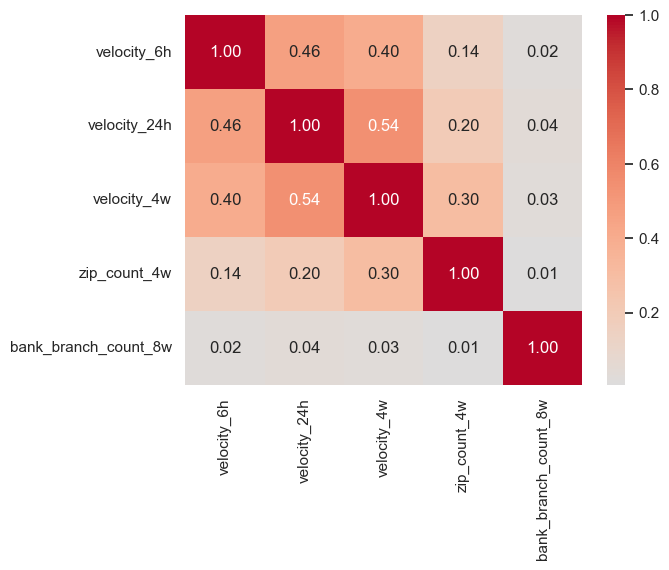

In [13]:
# Velocity qrupunda multikolinearlıq yoxlaması (korrelyasiya matrisi)
vel = ["velocity_6h", "velocity_24h", "velocity_4w", "zip_count_4w", "bank_branch_count_8w"]
sns.heatmap(df[vel].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

### Tək feature-in gücü (univariate AUC)
Hər sütunun tək başına fraud-u nə qədər ayırdığı. 0.5 = təsadüfi, uzaq olması = güclü siqnal.

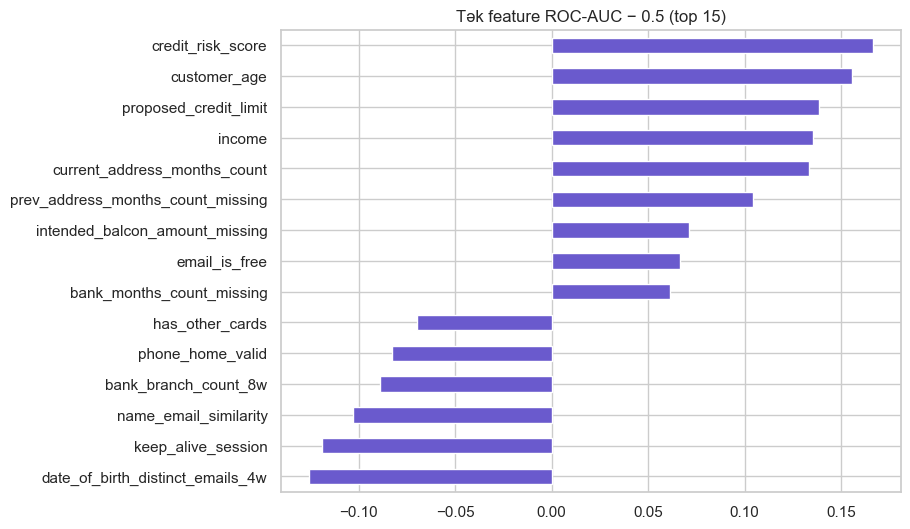

,roc_auc
credit_risk_score,0.666
customer_age,0.656
proposed_credit_limit,0.639
income,0.636
current_address_months_count,0.634
date_of_birth_distinct_emails_4w,0.374
keep_alive_session,0.381
prev_address_months_count_missing,0.604
name_email_similarity,0.397
bank_branch_count_8w,0.411


In [14]:
# Tək feature-in gücü: hər sütunun tək başına ROC-AUC-u (0.5 = siqnal yoxdur)
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score
from src.features import BAFCleaner

# Missing kodları NaN edilmiş data (BAFCleaner-in özü, pipeline-dakı ilə eyni məntiq)
clean = BAFCleaner().transform(df.drop(columns=[TARGET, TIME_COL]))

def univariate_auc(frame: pd.DataFrame, y: pd.Series) -> pd.Series:
    """Hər rəqəmsal sütunun tək başına ROC-AUC-u (NaN median ilə doldurulur)."""
    out = {}
    for c in frame.select_dtypes("number").columns:
        x = frame[c].fillna(frame[c].median())
        if x.nunique() > 1:
            out[c] = roc_auc_score(y, x)
    return pd.Series(out)

uni = univariate_auc(clean, df[TARGET])
strength = (uni - 0.5).abs().sort_values(ascending=False)
(uni.loc[strength.index[:15]] - 0.5).sort_values().plot(kind="barh", figsize=(8, 6), color="slateblue")
plt.title("Tək feature ROC-AUC − 0.5 (top 15)")
plt.show()
uni.loc[strength.index[:10]].round(3).to_frame("roc_auc")

### Sinfə görə paylanmalar
Fraud və legit müraciətlərin ən güclü rəqəmsal feature-lər üzrə paylanması (1%-99% kəsilmiş).

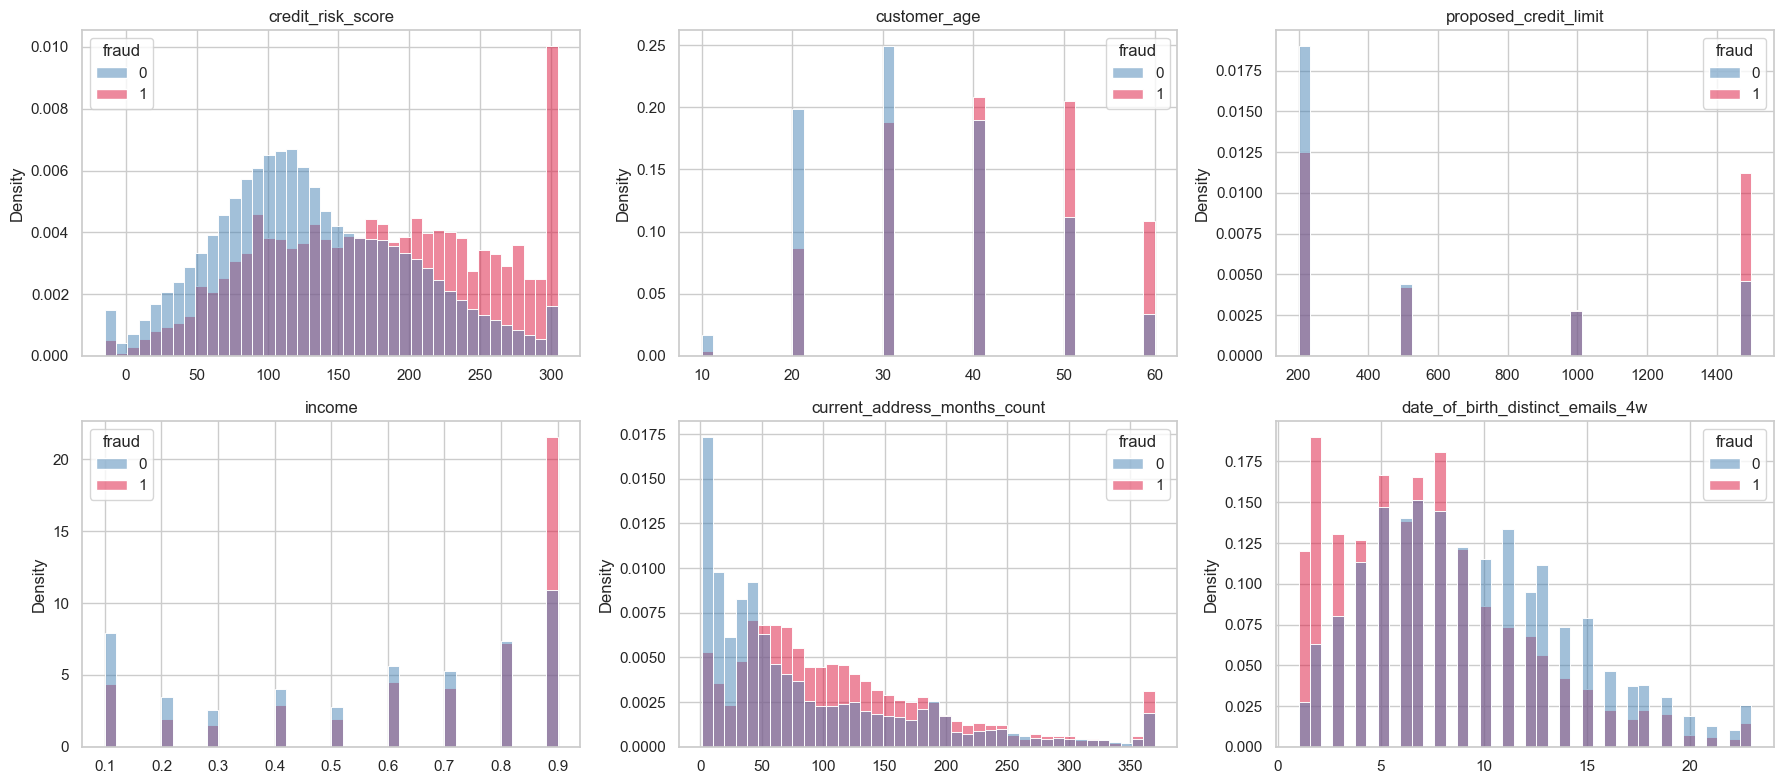

In [15]:
# Ən güclü 6 feature-in sinfə görə paylanması (1%-99% kəsilir ki, outlier qrafiki pozmasın)
top_cols = [c for c in strength.index if clean[c].nunique() > 2][:6]
sample = clean.assign(fraud=df[TARGET]).sample(300_000, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, c in zip(axes.ravel(), top_cols):
    lo, hi = sample[c].quantile([0.01, 0.99])
    tmp = pd.DataFrame({"x": sample[c].clip(lo, hi), "fraud": sample["fraud"]})
    sns.histplot(data=tmp, x="x", hue="fraud", stat="density", common_norm=False, bins=40, ax=ax, palette=["steelblue", "crimson"])
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout()
plt.show()

### Kateqorik əlaqə (Cramér's V)

In [16]:
# Cramér's V: kateqorik feature ilə target arasında əlaqənin gücü (0..1)
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    """Cramér's V (0..1): iki kateqorik dəyişən arasında əlaqənin gücü."""
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))

rates = {c: df.groupby(c)[TARGET].mean() for c in CATEGORICAL}
cat_tbl = pd.DataFrame({c: {"cramers_v": cramers_v(df[c], df[TARGET]), "n_levels": df[c].nunique(),
                            "min_fraud_rate": rates[c].min(), "max_fraud_rate": rates[c].max()} for c in CATEGORICAL}).T
cat_tbl.sort_values("cramers_v", ascending=False).round(4)

,cramers_v,n_levels,min_fraud_rate,max_fraud_rate
housing_status,0.1149,7.0,0.0034,0.0375
device_os,0.0805,5.0,0.0052,0.0247
employment_status,0.0397,7.0,0.0019,0.0247
payment_type,0.0391,5.0,0.0035,0.0167
source,0.0039,2.0,0.0110,0.0159


### Yaş qrupları üzrə baza fraud nisbəti (fairness konteksti)
Modelin yaş qruplarına fərqli davranmasının səbəbi real fraud nisbəti fərqidirmi?

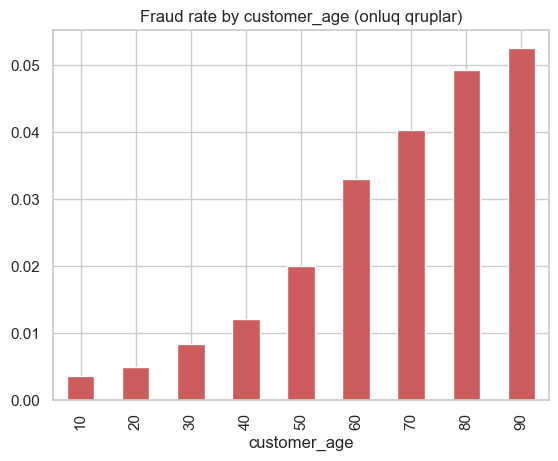

,fraud_rate,n
<50,0.0083,816987
>=50,0.0234,183013


In [17]:
# Yaş üzrə baza fraud nisbəti: fairness analizi üçün kontekst
age = df.groupby("customer_age")[TARGET].agg(fraud_rate="mean", n="count")
age["fraud_rate"].plot(kind="bar", color="indianred", title="Fraud rate by customer_age (onluq qruplar)")
plt.show()
older = df.groupby(df["customer_age"] >= 50)[TARGET].agg(fraud_rate="mean", n="count")
older.index = ["<50", ">=50"]
older.round(4)

### Missing indikatorlarının birgə görünməsi

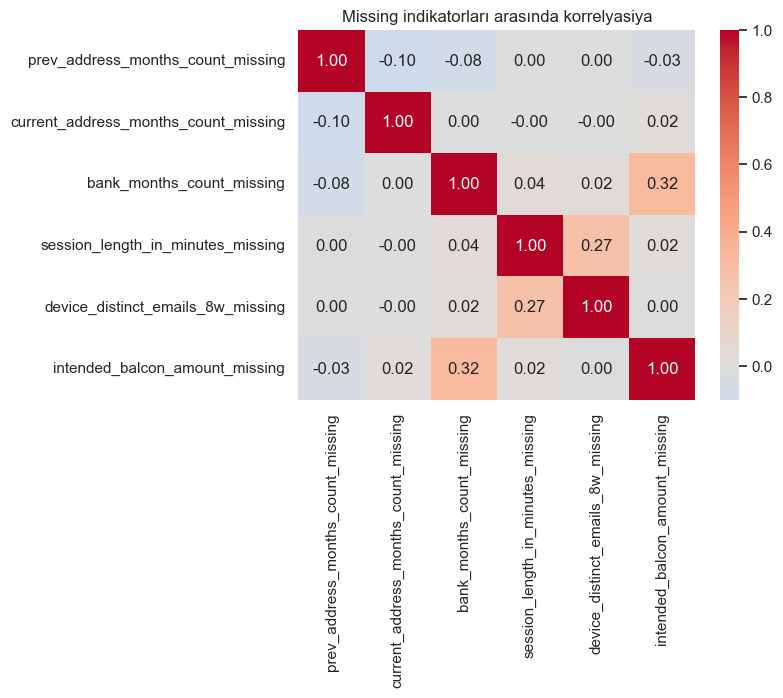

In [18]:
# Missing indikatorları bir-biri ilə nə qədər birgə görünür (korrelyasiya)
miss_cols = [c for c in clean.columns if c.endswith("_missing")]
sns.heatmap(clean[miss_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Missing indikatorları arasında korrelyasiya")
plt.show()

## 9. Time Dimension
`month` ilə fraud nisbəti: zamana görə split qərarının əsası.

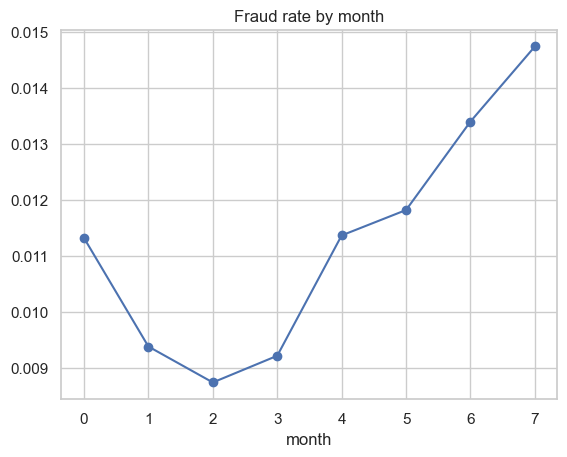

,mean,count
month,,
0,0.011326,132440
1,0.009387,127620
2,0.008746,136979
3,0.009222,150936
4,0.011371,127691
5,0.011825,119323
6,0.013405,108168
7,0.014746,96843


In [19]:
# Zaman ölçüsü: aylıq fraud nisbəti. Drift var, ona görə split zamana görə aparılır
by_month = df.groupby(TIME_COL)[TARGET].agg(["mean", "count"])
by_month["mean"].plot(marker="o", title="Fraud rate by month")
plt.show()
by_month

## 10. EDA Nəticələri → Qərarlar
| Müşahidə | Qərar |
|---|---|
| Sabit sütun | Drop |
| `-1` / mənfi gizli missing | NaN + missing indikator |
| Güclü imbalance | PR-AUC əsas metrik, class weight |
| Aylar üzrə fraud nisbəti dəyişir | Zamana görə split |
| Kənar dəyərlər fraud ilə qarışıq | Silmirik, scaling + tree modellər |